# 02_09 Von Mises (the circular Normal)

**Learning objectives**
- Recognize **circular data** (directions, times of day, phases) and see why ordinary statistics fail on a circle.
- Use the **circular mean** and the **mean resultant length**, and define the **von Mises** distribution with its location $\mu$ and concentration $\kappa$.
- Derive the density, the role of the Bessel function, the relation $\bar R=I_1(\kappa)/I_0(\kappa)$ and the link to the Normal for large $\kappa$.
- Solve three problems (wind direction, hour-of-day activity, animal bearings with a test of uniformity) by hand, in code and by simulation.

**Prerequisites:** [02_01 Uniform and Normal](02_01_uniform_normal.ipynb) (Normal density, mean, variance), basic trigonometry ($\cos$, $\sin$, $\arctan$).

## 1. Setup

All imports in one cell; the generator is seeded so every run gives the same numbers.

In [1]:
import sys
sys.path.append("../..")  # repo root, so common.style can be imported
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from scipy import stats
from common.style import apply_style, MAIN, SIM, HIGHLIGHT, NEUTRAL, COLORS

apply_style()
rng = np.random.default_rng(42)  # fixed seed so every run gives the same numbers

## 2. Prerequisite recap

- **Angles in radians:** a full circle is $2\pi$ radians $=360^\circ$; $\theta_{\text{rad}}=\theta_{\text{deg}}\cdot\pi/180$.
- **Unit vector of an angle:** $(\cos\theta,\sin\theta)$. Adding vectors, not angles, respects the circle.
- **`atan2(y, x)`:** the angle of the point $(x,y)$, in $(-\pi,\pi]$.
- **Normal distribution:** density $\propto e^{-(x-\mu)^2/(2\sigma^2)}$.
- **Taylor expansion:** $\cos u\approx1-u^2/2$ for small $u$.
- **Bessel function** $I_0(\kappa)=\dfrac1{2\pi}\int_{-\pi}^{\pi}e^{\kappa\cos\theta}d\theta=\sum_{j\ge0}\dfrac{(\kappa/2)^{2j}}{(j!)^2}$, a smooth increasing function with $I_0(0)=1$.

## 3. Intuition and story

### 3.1 Why the ordinary mean breaks on a circle
Three wind readings come from the directions $350^\circ$, $10^\circ$ and $0^\circ$ (all nearly due North). The arithmetic mean is $(350+10+0)/3=120^\circ$, which points South-East: nonsense. The problem is that $359^\circ$ and $1^\circ$ are only 2 degrees apart, but numerically far apart. The same trap appears for **hours of the day** (23:00 and 01:00), **months**, **phases** of a wave, and **compass bearings**.

The fix: turn every angle into a **unit vector** $(\cos\theta,\sin\theta)$, average the vectors, and read the angle of the average. This is the **circular mean**. The length of the average vector, the **mean resultant length** $\bar R\in[0,1]$, measures concentration: $\bar R=1$ when all directions agree, $\bar R\approx0$ when they are spread evenly around the circle.

arithmetic mean = 120.0 degrees (wrong), circular mean = 0.0 degrees, mean resultant length = 0.990


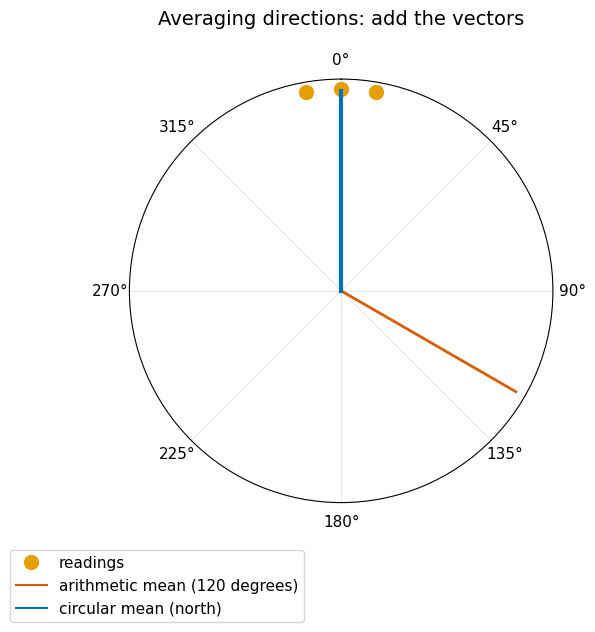

In [2]:
readings_deg = np.array([350.0, 10.0, 0.0])
readings = np.deg2rad(readings_deg)

arithmetic_mean_deg = readings_deg.mean()
x_mean = np.cos(readings).mean()
y_mean = np.sin(readings).mean()
circular_mean_deg = np.round(np.rad2deg(np.arctan2(y_mean, x_mean)), 6) % 360
resultant_length = np.hypot(x_mean, y_mean)

print(f"arithmetic mean = {arithmetic_mean_deg:.1f} degrees (wrong), circular mean = {circular_mean_deg:.1f} degrees, mean resultant length = {resultant_length:.3f}")

fig = plt.figure(figsize=(5.5, 5.5))
ax = fig.add_subplot(projection="polar")
ax.set_theta_zero_location("N")
ax.set_theta_direction(-1)
ax.plot(readings, np.ones(3), "o", color=SIM, markersize=10, label="readings")
ax.plot([np.deg2rad(arithmetic_mean_deg)] * 2, [0, 1], color=HIGHLIGHT, linewidth=2)         # an arrow is drawn as a line from the center
ax.plot([np.deg2rad(circular_mean_deg)] * 2, [0, resultant_length], color=MAIN, linewidth=3)
ax.plot([], [], color=HIGHLIGHT, label="arithmetic mean (120 degrees)")
ax.plot([], [], color=MAIN, label="circular mean (north)")
ax.set_title("Averaging directions: add the vectors", pad=20)
ax.set_yticks([])
ax.legend(loc="lower left", bbox_to_anchor=(-0.3, -0.3))
plt.show()

**In plain words.** To average angles, average the *arrows*. A long resulting arrow means the directions agree; a short one means they are scattered.

### 3.2 The Normal of the circle
The **von Mises distribution** is to the circle what the Normal is to the line. It is centered at a mean direction $\mu$ and has a concentration $\kappa$ (a "precision": large $\kappa$ means tightly concentrated). At $\kappa=0$ every direction is equally likely (uniform). For large $\kappa$ it looks like a Normal with variance $1/\kappa$, wrapped onto the circle.

## 4. Formal definition

**Von Mises($\mu,\kappa$):** support one full circle, $\theta\in[-\pi,\pi)$ (or any interval of length $2\pi$); mean direction $\mu$, concentration $\kappa\ge0$.
$$f(\theta)=\frac{e^{\kappa\cos(\theta-\mu)}}{2\pi I_0(\kappa)}.$$
The CDF has no closed form; it is the integral of $f$ from a chosen starting angle.

**Circular summaries.** For angles $\theta_1,\dots,\theta_n$: $\bar C=\frac1n\sum\cos\theta_i$, $\bar S=\frac1n\sum\sin\theta_i$,
$$\text{circular mean}=\operatorname{atan2}(\bar S,\bar C),\qquad\bar R=\sqrt{\bar C^2+\bar S^2},\qquad\text{circular variance}=1-\bar R.$$

**`scipy`:** `stats.vonmises(kappa, loc=mu)`; summaries `stats.circmean(angles, high=2*np.pi, low=0)`, `stats.circvar`, `stats.circstd`.

## 5. Derivations

### 5.1 Normalization
By definition $I_0(\kappa)=\frac1{2\pi}\int_{-\pi}^\pi e^{\kappa\cos\theta}d\theta$. The shift $\theta\to\theta-\mu$ does not change the integral over a full circle, so $\int f=1$. (The Bessel function is exactly the normalizing constant.)

### 5.2 Shape: why the formula is natural
The log-density is $\kappa\cos(\theta-\mu)+\text{const}$. The cosine is the simplest smooth periodic function with a single maximum at $\mu$, and $\kappa$ scales how sharply the density falls away from it. Among all circular distributions with a given mean direction and mean resultant length, the von Mises has **maximum entropy**, just like the Normal on the line.

### 5.3 Mean direction and the resultant length
By symmetry about $\mu$, $E[\sin(\theta-\mu)]=0$, so the mean direction is $\mu$. And
$$E[\cos(\theta-\mu)]=\frac1{2\pi I_0(\kappa)}\int_{-\pi}^\pi\cos u\,e^{\kappa\cos u}du=\frac{I_1(\kappa)}{I_0(\kappa)}=:A(\kappa),$$
because $I_0'(\kappa)=\frac1{2\pi}\int\cos u\,e^{\kappa\cos u}du=I_1(\kappa)$. Hence the **mean resultant length is $\bar R=A(\kappa)=I_1(\kappa)/I_0(\kappa)$**, and the circular variance is $1-A(\kappa)$. $A(0)=0$ (uniform), $A(\kappa)\to1$ as $\kappa\to\infty$. For large $\kappa$, $A(\kappa)\approx1-\frac1{2\kappa}$.

### 5.4 Large concentration: the Normal limit
Near $\mu$, $\cos u\approx1-u^2/2$, so $f(\theta)\propto\exp\!\big(-\kappa(\theta-\mu)^2/2\big)$: a **Normal with variance $\sigma^2=1/\kappa$** (and $I_0(\kappa)\approx e^\kappa/\sqrt{2\pi\kappa}$). So for $\kappa\gtrsim5$ the von Mises is practically a Normal around $\mu$.

### 5.5 Maximum likelihood
The log-likelihood is $\ell=\kappa\sum\cos(\theta_i-\mu)-n\ln(2\pi I_0(\kappa))$. Maximizing over $\mu$: $\hat\mu=\operatorname{atan2}(\sum\sin\theta_i,\sum\cos\theta_i)$, the circular mean. Setting $\partial\ell/\partial\kappa=0$ gives $A(\hat\kappa)=\bar R$: invert $\bar R=I_1(\kappa)/I_0(\kappa)$ numerically (or use an approximation: $\hat\kappa\approx\frac{\bar R(2-\bar R^2)}{1-\bar R^2}$).

### 5.6 Rayleigh test of uniformity
Under uniformity (no preferred direction), $n\bar R^2$ is approximately Exponential(1) for large $n$, so the p-value of the Rayleigh test is about $e^{-n\bar R^2}$ (a slightly more accurate version adds small corrections). A large $\bar R$ with many observations means the directions are not uniform.

### 5.7 Related distributions
- **Wrapped Normal:** a Normal on the line wrapped around the circle; very close to the von Mises.
- **Von Mises-Fisher:** the same idea on a sphere, $f(\mathbf x)\propto e^{\kappa\,\boldsymbol\mu^\top\mathbf x}$: directional statistics for embeddings and cosine similarity.
- **Uniform on the circle:** $\kappa=0$.

## 6. Properties and relationships

- **Circular, not linear:** angles $\theta$ and $\theta+2\pi$ are the same point; the density is periodic.
- **$\kappa$ is an inverse variance:** $\kappa=0$ uniform; $\kappa=1$ broad; $\kappa=10$ narrow (angular SD about $1/\sqrt{10}=0.32$ rad $=18^\circ$).
- **Normal limit** for large $\kappa$; **uniform** at $\kappa=0$.
- **Time of day as angle:** hour $h$ becomes $\theta=2\pi h/24$, so midnight is a smooth point and averages behave.
- **Convolution is not closed** (the sum of two von Mises is only approximately von Mises).
- **Estimation:** $\hat\mu$ is the circular mean; $\hat\kappa$ comes from $\bar R$.

## 7. 2D visuals

### 7.1 PDF and CDF on the line
The density of von Mises(mu = 0, kappa = 2) on [-pi, pi]; the CDF counts from -pi. The dotted lines show the density at mu plus or minus one angular standard deviation.

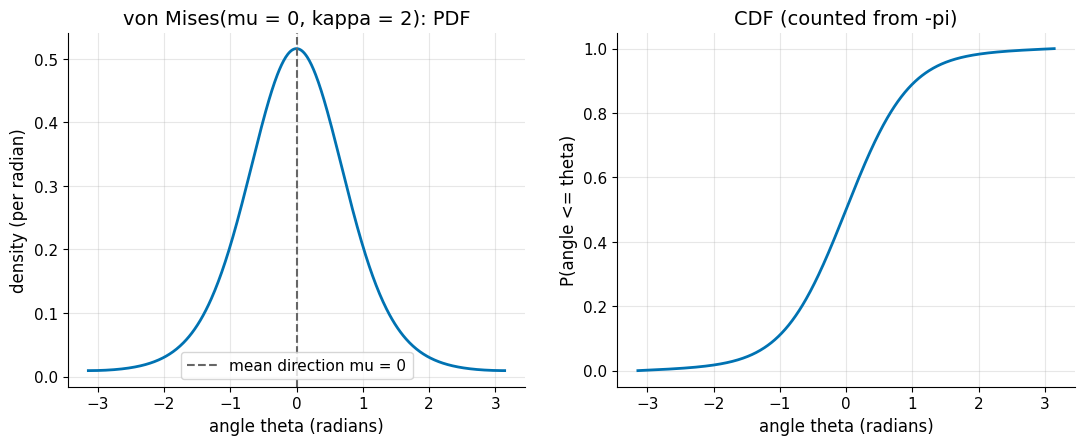

In [3]:
kappa, mu = 2.0, 0.0
dist = stats.vonmises(kappa, loc=mu)
theta = np.linspace(-np.pi, np.pi, 600)

fig, (ax_pdf, ax_cdf) = plt.subplots(1, 2, figsize=(13, 4.6))
ax_pdf.plot(theta, dist.pdf(theta), color=MAIN, linewidth=2)
ax_pdf.axvline(mu, color=NEUTRAL, linestyle="--", label="mean direction mu = 0")
ax_pdf.set_title("von Mises(mu = 0, kappa = 2): PDF")
ax_pdf.set_xlabel("angle theta (radians)")
ax_pdf.set_ylabel("density (per radian)")
ax_pdf.legend()

ax_cdf.plot(theta, dist.cdf(theta), color=MAIN, linewidth=2)
ax_cdf.set_title("CDF (counted from -pi)")
ax_cdf.set_xlabel("angle theta (radians)")
ax_cdf.set_ylabel("P(angle <= theta)")
plt.show()

### 7.2 Polar plot and the effect of kappa
On a circle the density is a curve around the origin: kappa = 0 is a perfect circle (uniform); larger kappa makes a lobe pointing at the mean direction.

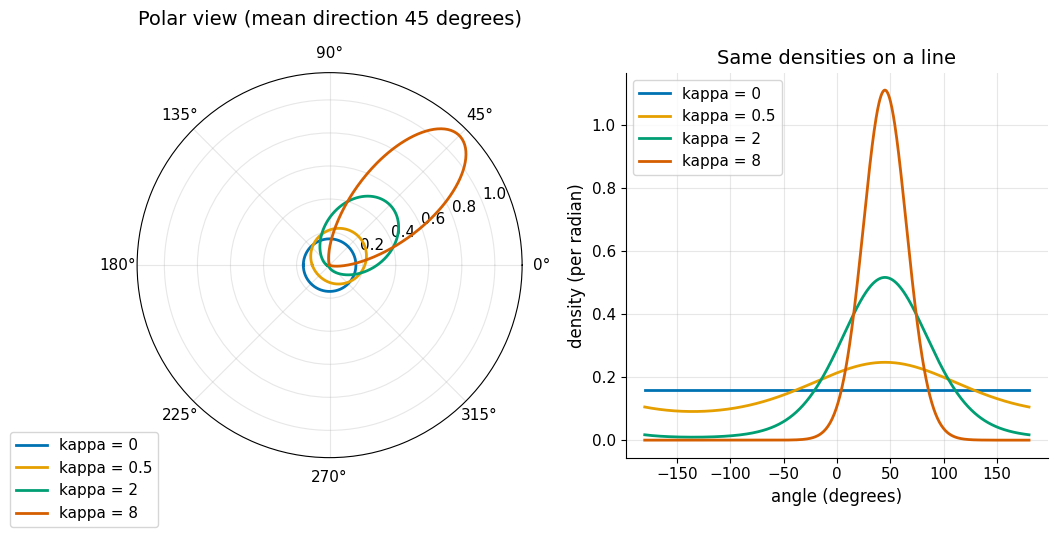

In [4]:
theta = np.linspace(-np.pi, np.pi, 800)
fig = plt.figure(figsize=(12, 5))
ax_polar = fig.add_subplot(1, 2, 1, projection="polar")
ax_line = fig.add_subplot(1, 2, 2)
ax_polar.set_theta_zero_location("E")
for kappa_value, color in zip([0, 0.5, 2, 8], COLORS):
    d = stats.vonmises(kappa_value, loc=np.deg2rad(45))
    ax_polar.plot(theta, d.pdf(theta), color=color, linewidth=2, label=f"kappa = {kappa_value}")
    ax_line.plot(np.rad2deg(theta), d.pdf(theta), color=color, linewidth=2, label=f"kappa = {kappa_value}")
ax_polar.set_title("Polar view (mean direction 45 degrees)", pad=15)
ax_polar.legend(loc="lower left", bbox_to_anchor=(-0.35, -0.2))
ax_line.set_title("Same densities on a line")
ax_line.set_xlabel("angle (degrees)")
ax_line.set_ylabel("density (per radian)")
ax_line.legend()
plt.show()

### 7.3 Mean resultant length versus kappa
The curve A(kappa) = I1(kappa) / I0(kappa) links the concentration to the mean resultant length. We use it to estimate kappa from data (section 5.5).

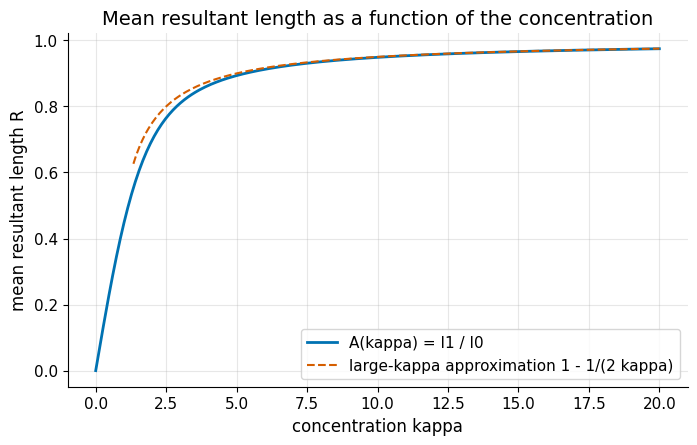

In [5]:
from scipy import special

kappa_axis = np.linspace(0, 20, 300)
resultant = special.i1(kappa_axis) / special.i0(kappa_axis)
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.plot(kappa_axis, resultant, color=MAIN, linewidth=2, label="A(kappa) = I1 / I0")
ax.plot(kappa_axis[20:], 1 - 1 / (2 * kappa_axis[20:]), "--", color=HIGHLIGHT, label="large-kappa approximation 1 - 1/(2 kappa)")
ax.set_title("Mean resultant length as a function of the concentration")
ax.set_xlabel("concentration kappa")
ax.set_ylabel("mean resultant length R")
ax.legend()
plt.show()

### 7.4 Large kappa: the Normal limit
For kappa = 10, the von Mises density is almost identical to a Normal with variance 1/kappa.

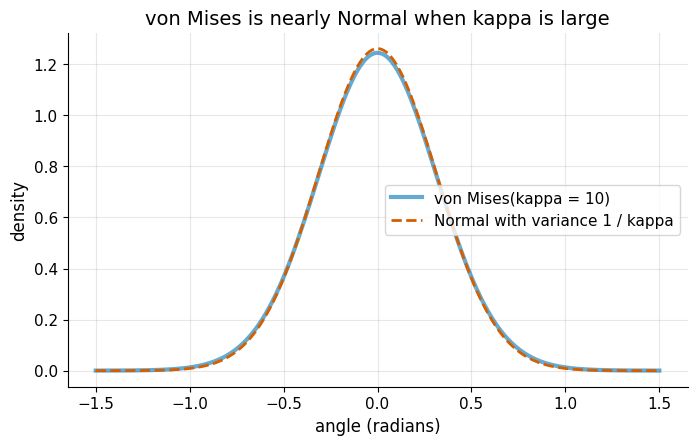

In [6]:
kappa_big = 10
theta = np.linspace(-1.5, 1.5, 400)
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.plot(theta, stats.vonmises(kappa_big).pdf(theta), color=MAIN, linewidth=3, alpha=0.6, label="von Mises(kappa = 10)")
ax.plot(theta, stats.norm(0, 1 / np.sqrt(kappa_big)).pdf(theta), "--", color=HIGHLIGHT, linewidth=2, label="Normal with variance 1 / kappa")
ax.set_title("von Mises is nearly Normal when kappa is large")
ax.set_xlabel("angle (radians)")
ax.set_ylabel("density")
ax.legend()
plt.show()

### 7.5 The wrapped Normal is almost the same
Wrapping a Normal(0, sigma^2) around the circle (adding all multiples of 2 pi) gives a very similar curve. We match the concentration by kappa = 1 / sigma^2 for moderate sigma, and check numerically.

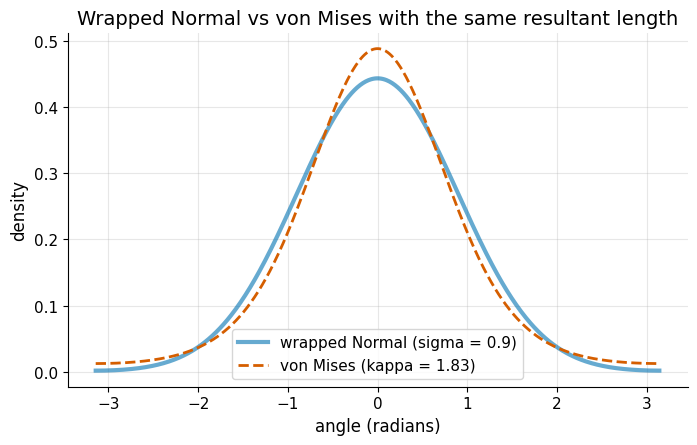

largest density difference: 0.0449


In [7]:
sigma = 0.9
shifts = np.arange(-6, 7)
wrapped = sum(stats.norm(0, sigma).pdf(theta_value + 2 * np.pi * shifts).sum() for theta_value in [0.0])
theta = np.linspace(-np.pi, np.pi, 600)
wrapped_pdf = np.array([stats.norm(0, sigma).pdf(t + 2 * np.pi * shifts).sum() for t in theta])
from scipy import optimize
kappa_matched = optimize.brentq(lambda k: special.i1(k) / special.i0(k) - np.exp(-sigma**2 / 2), 0.01, 50)     # same resultant length
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.plot(theta, wrapped_pdf, color=MAIN, linewidth=3, alpha=0.6, label="wrapped Normal (sigma = 0.9)")
ax.plot(theta, stats.vonmises(kappa_matched).pdf(theta), "--", color=HIGHLIGHT, linewidth=2, label=f"von Mises (kappa = {kappa_matched:.2f})")
ax.set_title("Wrapped Normal vs von Mises with the same resultant length")
ax.set_xlabel("angle (radians)")
ax.set_ylabel("density")
ax.legend()
plt.show()
print("largest density difference:", round(np.max(np.abs(wrapped_pdf - stats.vonmises(kappa_matched).pdf(theta))), 4))

## 8. 3D visuals

### 8.1 Static: PDF over (theta, kappa), mu = 0
A flat sheet at 1/(2 pi) for kappa = 0, rising into a sharper and sharper ridge at theta = 0 as kappa grows.

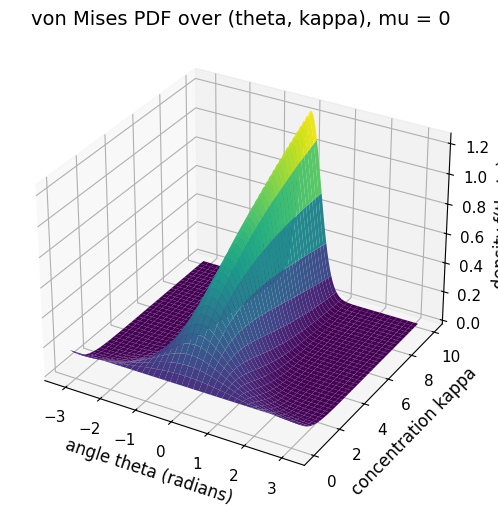

In [8]:
theta_values = np.linspace(-np.pi, np.pi, 160)
kappa_values = np.linspace(0, 10, 40)
T, K = np.meshgrid(theta_values, kappa_values)
Z = stats.vonmises.pdf(T, K)

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(projection="3d")
ax.plot_surface(T, K, Z, cmap="viridis", edgecolor="none")
ax.set_title("von Mises PDF over (theta, kappa), mu = 0")
ax.set_xlabel("angle theta (radians)")
ax.set_ylabel("concentration kappa")
ax.set_zlabel("density f(theta)")
ax.view_init(elev=30, azim=-60)
plt.show()

### 8.2 Static: the density as a ring on the circle
Each angle on the circle (x = cos theta, y = sin theta) gets a height equal to the density. This 3D ring is the most faithful picture of a circular distribution.

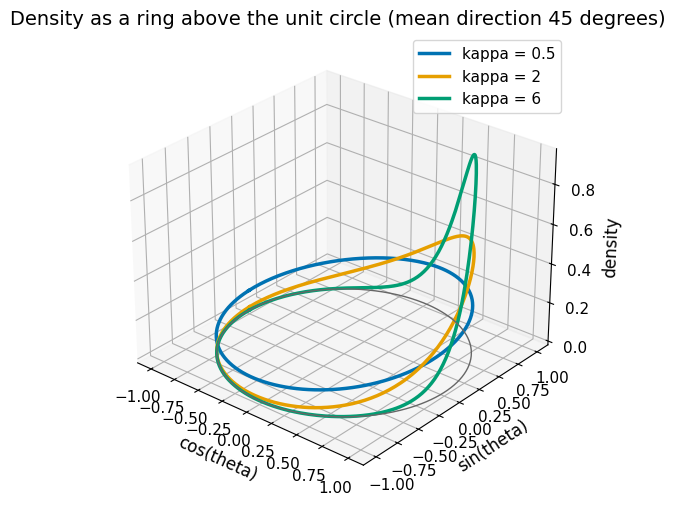

In [9]:
angles = np.linspace(-np.pi, np.pi, 400)
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(projection="3d")
for kappa_value, color in zip([0.5, 2, 6], COLORS):
    density = stats.vonmises(kappa_value, loc=np.deg2rad(45)).pdf(angles)
    ax.plot(np.cos(angles), np.sin(angles), density, color=color, linewidth=2.5, label=f"kappa = {kappa_value}")
ax.plot(np.cos(angles), np.sin(angles), np.zeros_like(angles), color=NEUTRAL, linewidth=1)
ax.set_title("Density as a ring above the unit circle (mean direction 45 degrees)")
ax.set_xlabel("cos(theta)")
ax.set_ylabel("sin(theta)")
ax.set_zlabel("density")
ax.view_init(elev=28, azim=-50)
ax.legend()
plt.show()

### 8.3 Interactive Plotly version
The (theta, kappa) surface of 8.1; drag to rotate and hover.

In [10]:
fig = go.Figure(go.Surface(x=theta_values, y=kappa_values, z=Z, colorscale="Viridis"))
fig.update_layout(title="von Mises PDF over (theta, kappa), mu = 0", width=750, height=550,
                  scene=dict(xaxis_title="angle theta (radians)", yaxis_title="concentration kappa", zaxis_title="density f(theta)"))
fig.show()

## 9. Simulation vs theory

### 9.1 Histogram against the PDF
50,000 directions from von Mises(mu = 45 degrees, kappa = 3).

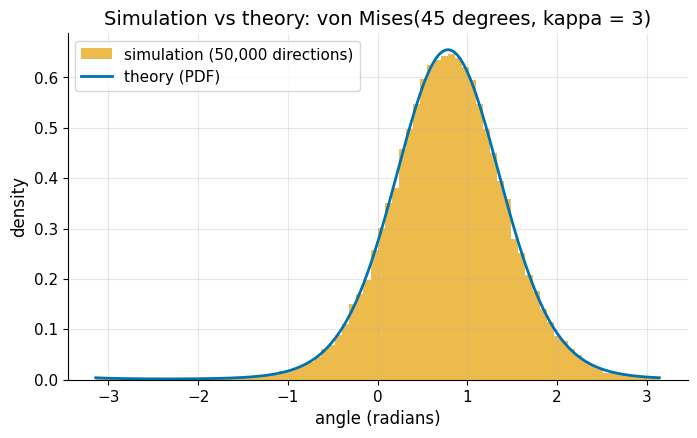

circular mean = 45.04 degrees (true 45); R = 0.8113 (theory A(3) = 0.8100)


In [11]:
mu_true, kappa_true = np.deg2rad(45), 3.0
samples = rng.vonmises(mu_true, kappa_true, size=50_000)       # numpy returns angles in (-pi, pi]
theta = np.linspace(-np.pi, np.pi, 600)

fig, ax = plt.subplots()
ax.hist(samples, bins=80, density=True, color=SIM, alpha=0.7, label="simulation (50,000 directions)")
ax.plot(theta, stats.vonmises(kappa_true, loc=mu_true).pdf(theta), color=MAIN, linewidth=2, label="theory (PDF)")
ax.set_title("Simulation vs theory: von Mises(45 degrees, kappa = 3)")
ax.set_xlabel("angle (radians)")
ax.set_ylabel("density")
ax.legend()
plt.show()
mean_direction = np.arctan2(np.sin(samples).mean(), np.cos(samples).mean())
resultant = np.hypot(np.sin(samples).mean(), np.cos(samples).mean())
print(f"circular mean = {np.rad2deg(mean_direction):.2f} degrees (true 45); R = {resultant:.4f} (theory A(3) = {special.i1(3) / special.i0(3):.4f})")

### 9.2 The running resultant converges
The running circular mean converges to mu and the running mean resultant length to A(kappa). (The linear mean of the angles does so only when no data wrap around the cut point.)

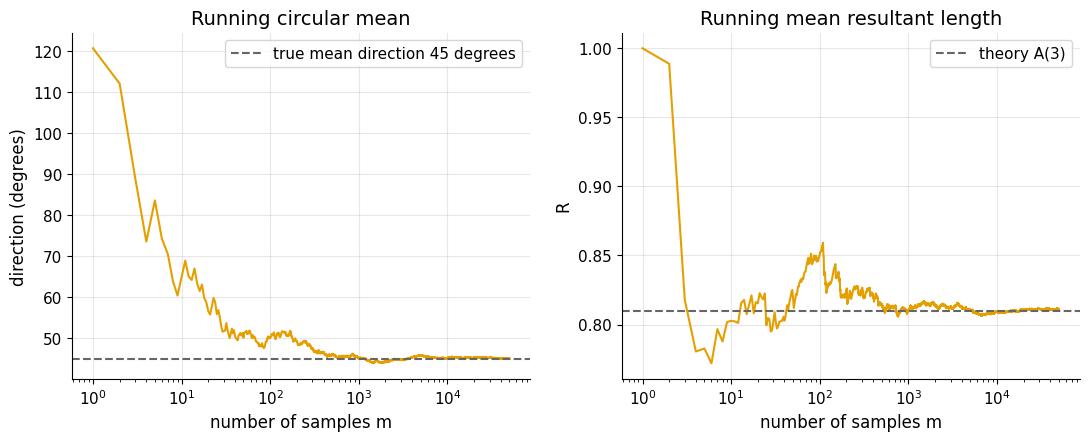

In [12]:
m_values = np.arange(1, len(samples) + 1)
running_direction = np.rad2deg(np.arctan2(np.cumsum(np.sin(samples)) / m_values, np.cumsum(np.cos(samples)) / m_values))
running_length = np.hypot(np.cumsum(np.sin(samples)) / m_values, np.cumsum(np.cos(samples)) / m_values)

fig, (ax_dir, ax_len) = plt.subplots(1, 2, figsize=(13, 4.5))
ax_dir.plot(m_values, running_direction, color=SIM)
ax_dir.axhline(45, color=NEUTRAL, linestyle="--", label="true mean direction 45 degrees")
ax_dir.set_xscale("log")
ax_dir.set_title("Running circular mean")
ax_dir.set_xlabel("number of samples m")
ax_dir.set_ylabel("direction (degrees)")
ax_dir.legend()
ax_len.plot(m_values, running_length, color=SIM)
ax_len.axhline(special.i1(3) / special.i0(3), color=NEUTRAL, linestyle="--", label="theory A(3)")
ax_len.set_xscale("log")
ax_len.set_title("Running mean resultant length")
ax_len.set_xlabel("number of samples m")
ax_len.set_ylabel("R")
ax_len.legend()
plt.show()

### 9.3 Estimating kappa from data (maximum likelihood)
We repeat the experiment 2,000 times with n = 50 observations, estimate kappa from the resultant length (inverting A(kappa)), and compare the average estimate with the truth.

In [13]:
def estimate_kappa(angles):
    """Invert A(kappa) = I1(kappa) / I0(kappa) = R by root finding (maximum likelihood)."""
    r = np.hypot(np.sin(angles).mean(), np.cos(angles).mean())
    return optimize.brentq(lambda k: special.i1(k) / special.i0(k) - r, 1e-6, 500)

estimates = [estimate_kappa(rng.vonmises(mu_true, kappa_true, size=50)) for _ in range(2000)]
print(f"true kappa = {kappa_true}; mean estimate = {np.mean(estimates):.3f}; SD of estimates = {np.std(estimates):.3f}")
fitted_kappa, fitted_loc, _ = stats.vonmises.fit(samples, fscale=1)
print(f"scipy fit on 50,000 samples: kappa = {fitted_kappa:.3f}, mu = {np.rad2deg(fitted_loc):.2f} degrees")

true kappa = 3.0; mean estimate = 3.162; SD of estimates = 0.591
scipy fit on 50,000 samples: kappa = 3.018, mu = 45.04 degrees


## 10. `scipy.stats` cheat sheet

In [14]:
d = stats.vonmises(kappa=4, loc=np.deg2rad(45))
print("pdf at the mean direction     :", round(d.pdf(np.deg2rad(45)), 4))
print("cdf(45 deg) - cdf(-45 deg)    :", round(d.cdf(np.deg2rad(45)) - d.cdf(np.deg2rad(-45)), 4), "(probability within a 90-degree window)")
print("rvs(3) in degrees             :", np.rad2deg(d.rvs(size=3, random_state=1)).round(1))
print("std (angular, radians)        :", round(d.std(), 4), "  circular variance 1 - R:", round(1 - special.i1(4) / special.i0(4), 4))

angles = np.deg2rad([350, 10, 0, 20, 340])
print("circmean (degrees)            :", round(np.rad2deg(stats.circmean(angles, high=np.pi, low=-np.pi)), 2) + 0.0)
print("circvar, circstd              :", round(stats.circvar(angles, high=np.pi, low=-np.pi), 4), round(stats.circstd(angles, high=np.pi, low=-np.pi), 4))

pdf at the mean direction     : 0.7689
cdf(45 deg) - cdf(-45 deg)    : 0.4962 (probability within a 90-degree window)
rvs(3) in degrees             : [23.3 30.4 36.4]


std (angular, radians)        : 0.5461   circular variance 1 - R: 0.1365
circmean (degrees)            : 0.0
circvar, circstd              : 0.0302 0.2476


**Fitting:** `stats.vonmises.fit(data, fscale=1)` returns (kappa, loc, scale) with the scale fixed at 1. The location is the circular mean (modulo $2\pi$).

## 11. Real-world worked examples

---
### Example 1 (main): wind direction at a site

**Scenario (illustrative numbers).** Wind direction (degrees clockwise from North) at a coastal site follows a von Mises distribution with **mean direction $\mu=45^\circ$ (North-East)** and **concentration $\kappa=4$**.

**Questions**
1. What is the probability that the wind comes from **within $\pm30^\circ$ of North-East**?
2. What is the probability that it comes from the **opposite half-circle** (more than $90^\circ$ from North-East, the wrong side for a sea-facing harbor)?
3. Six hourly readings are $350^\circ,\,10^\circ,\,5^\circ,\,20^\circ,\,355^\circ,\,15^\circ$. What is their **circular mean**, and what would the arithmetic mean give?

### 11.1 By hand
**Q1.** $P=\displaystyle\int_{-\pi/6}^{\pi/6}\frac{e^{4\cos u}}{2\pi I_0(4)}du$ with $u=\theta-\mu$. The Bessel constant: $I_0(4)=\sum_j\frac{2^{2j}\cdot2^{2j}}{(j!)^2}\cdot\frac{1}{1}$ evaluates to $I_0(4)=11.3019$. The integral has no closed form, so we apply the trapezoid rule in a plain loop below. Reasoning check: the angular SD is about $1/\sqrt4=0.5$ rad $=29^\circ$, so $\pm30^\circ$ is about $\pm1$ SD, giving roughly 68 %.

**Q2.** $P(|u|>\pi/2)=1-\displaystyle\int_{-\pi/2}^{\pi/2}f(u)du$ (the integral over the near half circle). Since $\kappa=4$ is fairly concentrated, expect a small probability.

**Q3.** Compute the mean of $\cos$ and of $\sin$ and take the angle of the resulting vector. Because the readings straddle $0^\circ/360^\circ$ the arithmetic mean $(350+10+5+20+355+15)/6=125.8^\circ$ is wrong, while the circular mean is near $6^\circ$.

In [15]:
import math

kappa_wind, mu_wind = 4.0, math.radians(45)

def bessel_i0_by_series(kappa, terms=40):
    # I0(kappa) = sum_j (kappa / 2)^(2j) / (j!)^2, written as an explicit loop
    total = 0.0
    for j in range(terms):
        total += (kappa / 2) ** (2 * j) / math.factorial(j) ** 2
    return total

def von_mises_pdf_by_formula(u, kappa):
    # exp(kappa cos u) / (2 pi I0(kappa))   (u = angle minus mean direction)
    return math.exp(kappa * math.cos(u)) / (2 * math.pi * bessel_i0_by_series(kappa))

def integrate_density(lower, upper, kappa, steps=20_000):
    # trapezoid rule, plain loop
    width = (upper - lower) / steps
    area = 0.0
    previous = von_mises_pdf_by_formula(lower, kappa)
    for i in range(1, steps + 1):
        current = von_mises_pdf_by_formula(lower + i * width, kappa)
        area += 0.5 * (previous + current) * width
        previous = current
    return area

p_within_30_hand = integrate_density(-math.pi / 6, math.pi / 6, kappa_wind)
p_opposite_hand = 1 - integrate_density(-math.pi / 2, math.pi / 2, kappa_wind)

readings_deg = [350, 10, 5, 20, 355, 15]
x_total = sum(math.cos(math.radians(a)) for a in readings_deg) / len(readings_deg)
y_total = sum(math.sin(math.radians(a)) for a in readings_deg) / len(readings_deg)
circular_mean_hand = round(math.degrees(math.atan2(y_total, x_total)), 6) % 360
arithmetic_mean = sum(readings_deg) / len(readings_deg)
print(f"I0(4) = {bessel_i0_by_series(4):.4f}; P(within +-30 degrees) = {p_within_30_hand:.4f}; P(opposite half) = {p_opposite_hand:.4f}")
print(f"circular mean = {circular_mean_hand:.2f} degrees, arithmetic mean = {arithmetic_mean:.1f} degrees")

I0(4) = 11.3019; P(within +-30 degrees) = 0.6807; P(opposite half) = 0.0076
circular mean = 5.85 degrees, arithmetic mean = 125.8 degrees


### 11.2 In code with `scipy`, and the asserts

In [16]:
wind = stats.vonmises(kappa_wind, loc=mu_wind)

p_within_30_code = wind.cdf(mu_wind + math.pi / 6) - wind.cdf(mu_wind - math.pi / 6)
p_opposite_code = 1 - (wind.cdf(mu_wind + math.pi / 2) - wind.cdf(mu_wind - math.pi / 2))
circular_mean_code = round(float(np.rad2deg(stats.circmean(np.deg2rad(readings_deg), high=2 * np.pi, low=0))), 6) % 360

assert np.isclose(bessel_i0_by_series(4), special.i0(4))
assert np.isclose(p_within_30_hand, p_within_30_code, atol=1e-6)
assert np.isclose(p_opposite_hand, p_opposite_code, atol=1e-6)
assert np.isclose(circular_mean_hand, circular_mean_code)
print(f"P(within 30 degrees of NE) = {p_within_30_code:.4f}; P(opposite half-circle) = {p_opposite_code:.4f}")
print(f"circular mean = {circular_mean_code:.2f} degrees; mean resultant length = {np.hypot(x_total, y_total):.4f}")

P(within 30 degrees of NE) = 0.6807; P(opposite half-circle) = 0.0076
circular mean = 5.85 degrees; mean resultant length = 0.9831


### 11.3 Verify by simulation

In [17]:
simulated = rng.vonmises(mu_wind, kappa_wind, size=1_000_000)
difference = np.angle(np.exp(1j * (simulated - mu_wind)))               # angular difference wrapped to (-pi, pi]
print(f"P(within +-30 degrees): exact {p_within_30_code:.4f}, simulated {np.mean(np.abs(difference) <= math.pi / 6):.4f}")
print(f"P(opposite half):       exact {p_opposite_code:.4f}, simulated {np.mean(np.abs(difference) > math.pi / 2):.4f}")
mean_dir_sim = np.rad2deg(np.arctan2(np.sin(simulated).mean(), np.cos(simulated).mean())) % 360
print(f"simulated circular mean = {mean_dir_sim:.2f} degrees (true 45); R = {np.hypot(np.sin(simulated).mean(), np.cos(simulated).mean()):.4f} (theory {special.i1(4) / special.i0(4):.4f})")
assert abs(np.mean(np.abs(difference) <= math.pi / 6) - p_within_30_code) < 0.002

P(within +-30 degrees): exact 0.6807, simulated 0.6813
P(opposite half):       exact 0.0076, simulated 0.0075
simulated circular mean = 44.96 degrees (true 45); R = 0.8637 (theory 0.8635)


### 11.4 Plots

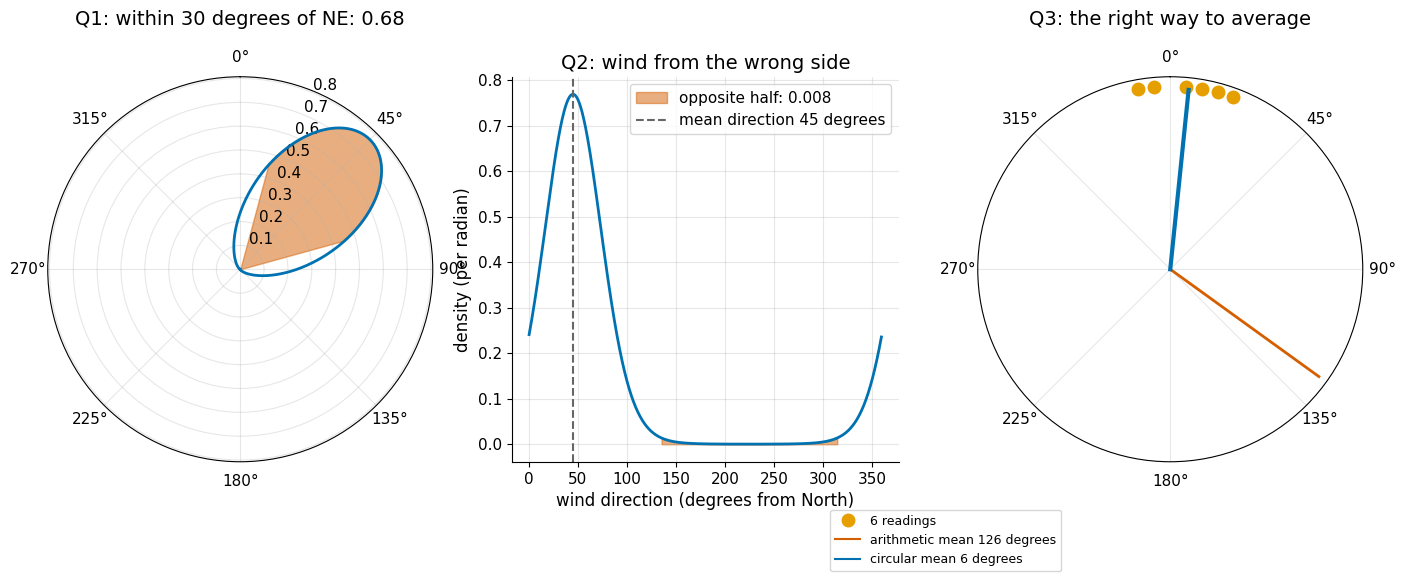

In [18]:
theta = np.linspace(-np.pi, np.pi, 800)
fig = plt.figure(figsize=(17, 5))
ax_polar = fig.add_subplot(1, 3, 1, projection="polar")
ax_polar.set_theta_zero_location("N")
ax_polar.set_theta_direction(-1)
ax_polar.plot(theta, wind.pdf(theta), color=MAIN, linewidth=2)
inside = np.abs(np.angle(np.exp(1j * (theta - mu_wind)))) <= math.pi / 6
ax_polar.fill_between(theta[inside], 0, wind.pdf(theta[inside]), color=HIGHLIGHT, alpha=0.5)
ax_polar.set_title(f"Q1: within 30 degrees of NE: {p_within_30_code:.2f}", pad=18)

ax_line = fig.add_subplot(1, 3, 2)
degrees = np.rad2deg(theta) % 360
order = np.argsort(degrees)
ax_line.plot(degrees[order], wind.pdf(theta)[order], color=MAIN, linewidth=2)
opposite = np.abs(np.angle(np.exp(1j * (theta - mu_wind)))) > math.pi / 2
ax_line.fill_between(degrees[order], wind.pdf(theta)[order], where=opposite[order], color=HIGHLIGHT, alpha=0.5, label=f"opposite half: {p_opposite_code:.3f}")
ax_line.axvline(45, color=NEUTRAL, linestyle="--", label="mean direction 45 degrees")
ax_line.set_title("Q2: wind from the wrong side")
ax_line.set_xlabel("wind direction (degrees from North)")
ax_line.set_ylabel("density (per radian)")
ax_line.legend()

ax_data = fig.add_subplot(1, 3, 3, projection="polar")
ax_data.set_theta_zero_location("N")
ax_data.set_theta_direction(-1)
ax_data.plot(np.deg2rad(readings_deg), np.ones(len(readings_deg)), "o", color=SIM, markersize=9, label="6 readings")
ax_data.plot([math.radians(arithmetic_mean)] * 2, [0, 1], color=HIGHLIGHT, linewidth=2)
ax_data.plot([math.radians(circular_mean_code)] * 2, [0, np.hypot(x_total, y_total)], color=MAIN, linewidth=3)
ax_data.plot([], [], color=HIGHLIGHT, label=f"arithmetic mean {arithmetic_mean:.0f} degrees")
ax_data.plot([], [], color=MAIN, label=f"circular mean {circular_mean_code:.0f} degrees")
ax_data.set_yticks([])
ax_data.set_title("Q3: the right way to average", pad=18)
ax_data.legend(loc="lower left", bbox_to_anchor=(-0.4, -0.3), fontsize=9)
plt.show()

### 11.5 Interpretation and decision
- **About 68 % of the time (0.68) the wind is within 30 degrees of North-East**, the main direction: a turbine or sail rig can be optimized for that direction.
- The probability of wind from the **opposite half-circle is only about 0.8 %**; the harbor entrance is well protected the large majority of the time.
- The **circular mean of the six readings is about 6 degrees (roughly North)**, while the arithmetic mean says 126 degrees (South-East): a completely wrong answer. Always use circular statistics for directions.
- **Decision:** orient the equipment toward 45 degrees, plan for the rare opposite wind with a safety rule, and always summarize directions with the circular mean and the concentration kappa.

---
### Example 2: hour-of-day activity

**Scenario (illustrative).** An app's user activity peaks at **20:00** (8 pm) with concentration **$\kappa=1.5$** over the 24-hour clock. Map hour $h$ to the angle $	heta=2\pi h/24$.

**Questions:** (a) the probability that activity falls between **18:00 and 22:00**; (b) why the ordinary average of the hours fails for night-time users with readings 23, 0, 1, 23.5 and 0.5; (c) the circular mean of those readings.

**By hand.** (a) 18:00 to 22:00 is $\pm2$ hours around the peak, i.e. $\pm\pi/12\cdot2=\pm30^\circ$ ($\pm\pi/6$ rad): integrate $f(u)$ over $u\in[-\pi/6,\pi/6]$ with $\kappa=1.5$ (the same routine). (b) The arithmetic mean is $(23+0+1+23.5+0.5)/5=9.6$ h, mid-morning for night-owls: wrong. (c) the circular mean of the hour angles is midnight (0.0 h), as the readings are symmetric around it.

In [19]:
kappa_hours = 1.5
hours_to_angle = lambda h: 2 * math.pi * h / 24
p_active_18_22_hand = integrate_density(-hours_to_angle(2), hours_to_angle(2), kappa_hours)

activity = stats.vonmises(kappa_hours, loc=hours_to_angle(20))
p_active_18_22_code = activity.cdf(hours_to_angle(22)) - activity.cdf(hours_to_angle(18))
assert np.isclose(p_active_18_22_hand, p_active_18_22_code, atol=1e-6)

night_hours = np.array([23, 0, 1, 23.5, 0.5])
circular_mean_hours = round(float(stats.circmean(night_hours, high=24, low=0)), 6) % 24
print(f"P(activity between 18:00 and 22:00) = {p_active_18_22_code:.4f}")
print(f"night readings: arithmetic mean = {night_hours.mean():.1f} h (wrong), circular mean = {circular_mean_hours:.2f} h, resultant R = {1 - stats.circvar(night_hours, high=24, low=0):.3f}")

simulated_hours = rng.vonmises(hours_to_angle(20), kappa_hours, size=500_000) * 24 / (2 * math.pi) % 24
print(f"simulation: P(18 <= hour <= 22) = {np.mean((simulated_hours >= 18) & (simulated_hours <= 22)):.4f}")
assert abs(np.mean((simulated_hours >= 18) & (simulated_hours <= 22)) - p_active_18_22_code) < 0.003

P(activity between 18:00 and 22:00) = 0.4247
night readings: arithmetic mean = 9.6 h (wrong), circular mean = 0.00 h, resultant R = 0.983
simulation: P(18 <= hour <= 22) = 0.4250


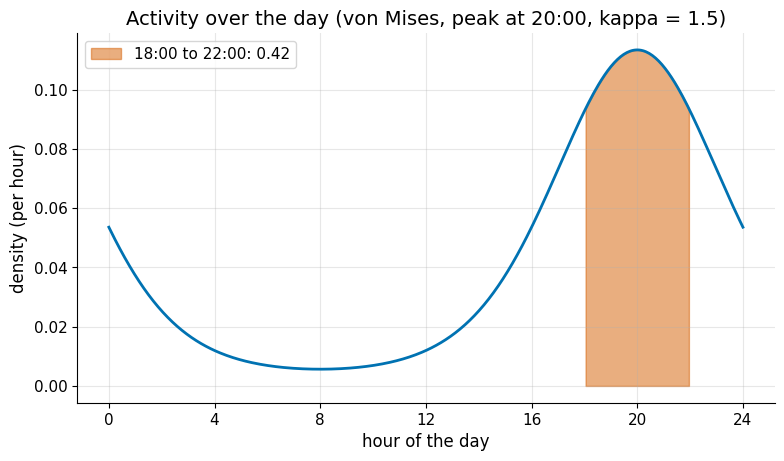

In [20]:
hours = np.linspace(0, 24, 400)
fig, ax = plt.subplots(figsize=(9, 4.8))
density_per_hour = activity.pdf(hours_to_angle(hours) - 2 * math.pi * (hours > 12)) * 2 * math.pi / 24
ax.plot(hours, density_per_hour, color=MAIN, linewidth=2)
window = (hours >= 18) & (hours <= 22)
ax.fill_between(hours[window], density_per_hour[window], color=HIGHLIGHT, alpha=0.5, label=f"18:00 to 22:00: {p_active_18_22_code:.2f}")
ax.set_xticks(range(0, 25, 4))
ax.set_title("Activity over the day (von Mises, peak at 20:00, kappa = 1.5)")
ax.set_xlabel("hour of the day")
ax.set_ylabel("density (per hour)")
ax.legend()
plt.show()

**Interpretation.** About **42 % of the activity** falls in the four-hour evening window around the peak, so that is the time for notifications and releases. For the night-owls the naive average (9.6 h) would schedule support at the wrong time of day; the circular mean (midnight, 0.0 h) is correct.

---
### Example 3: animal bearings and the Rayleigh test of uniformity

**Scenario (illustrative).** The departure bearings of $n=40$ birds are recorded. Their mean resultant length is $ar R=0.45$. Do the birds prefer a direction, or are they flying in random directions?

**By hand.** Under uniformity, $nar R^2$ is approximately Exponential(1). $nar R^2=40	imes0.45^2=8.10$, so the approximate p-value is $e^{-8.10}=0.0003$. We **reject uniformity**: the birds have a preferred direction.

In [21]:
n_birds, resultant_observed = 40, 0.45
z_statistic = n_birds * resultant_observed**2
p_value_hand = math.exp(-z_statistic)
print(f"Rayleigh statistic n R^2 = {z_statistic:.2f}, approximate p-value = {p_value_hand:.5f}")

# Simulation under the null: 40 uniformly random directions, many times
uniform_angles = rng.uniform(-np.pi, np.pi, size=(200_000, n_birds))
r_values = np.hypot(np.sin(uniform_angles).mean(axis=1), np.cos(uniform_angles).mean(axis=1))
p_value_sim = np.mean(r_values >= resultant_observed)
print(f"simulated p-value (R >= {resultant_observed}) = {p_value_sim:.5f}; 95th percentile of R under uniformity = {np.percentile(r_values, 95):.3f}")
assert p_value_hand < 0.001 and p_value_sim < 0.001
assert np.isclose(np.mean(n_birds * r_values**2 >= 3.0), math.exp(-3.0), atol=0.005)       # the Exponential(1) approximation holds

# estimate how concentrated the birds are
kappa_estimate = optimize.brentq(lambda k: special.i1(k) / special.i0(k) - resultant_observed, 1e-6, 100)
print(f"estimated concentration kappa = {kappa_estimate:.2f}; angular SD about {np.rad2deg(1 / np.sqrt(kappa_estimate)):.0f} degrees")

Rayleigh statistic n R^2 = 8.10, approximate p-value = 0.00030


simulated p-value (R >= 0.45) = 0.00020; 95th percentile of R under uniformity = 0.272
estimated concentration kappa = 1.01; angular SD about 57 degrees


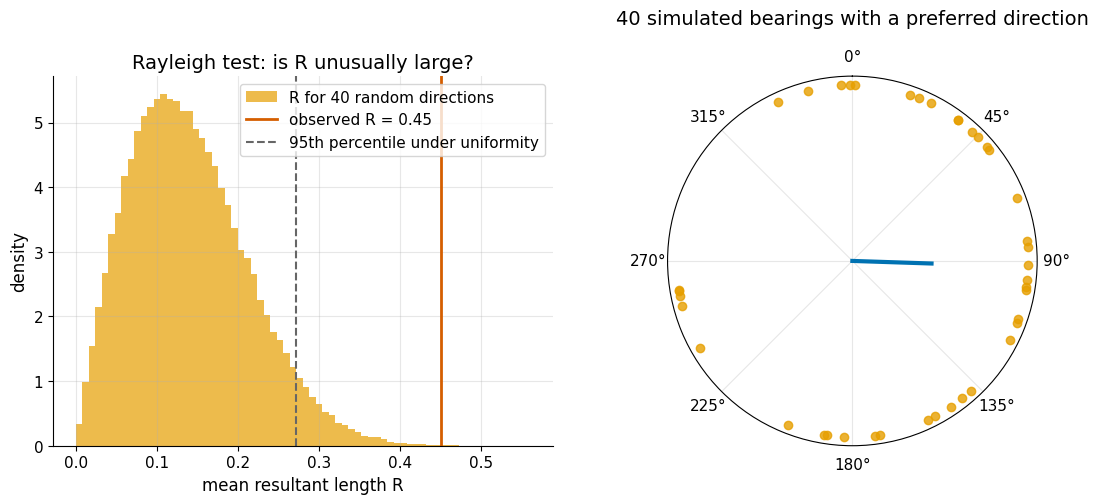

In [22]:
fig, (ax_null, ax_birds) = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1.2, 1]})
ax_null.hist(r_values, bins=70, density=True, color=SIM, alpha=0.7, label="R for 40 random directions")
ax_null.axvline(resultant_observed, color=HIGHLIGHT, linewidth=2, label=f"observed R = {resultant_observed}")
ax_null.axvline(np.percentile(r_values, 95), color=NEUTRAL, linestyle="--", label="95th percentile under uniformity")
ax_null.set_title("Rayleigh test: is R unusually large?")
ax_null.set_xlabel("mean resultant length R")
ax_null.set_ylabel("density")
ax_null.legend()

bird_angles = rng.vonmises(np.deg2rad(120), kappa_estimate, size=n_birds)
ax_birds.remove()
ax_polar = fig.add_subplot(1, 2, 2, projection="polar")
ax_polar.set_theta_zero_location("N")
ax_polar.set_theta_direction(-1)
ax_polar.plot(bird_angles, np.ones(n_birds), "o", color=SIM, alpha=0.8)
ax_polar.plot([np.arctan2(np.sin(bird_angles).mean(), np.cos(bird_angles).mean())] * 2, [0, resultant_observed], color=MAIN, linewidth=3)
ax_polar.set_yticks([])
ax_polar.set_title("40 simulated bearings with a preferred direction", pad=18)
plt.show()

**Interpretation.** With 40 birds, an R of 0.45 would almost never occur by chance if directions were random (the 95th percentile under uniformity is only about 0.27): **the birds have a real preferred direction**, with an estimated concentration of about 1, an angular SD of about 57 degrees. The Rayleigh test is the circular analogue of testing a mean against zero.

## 12. Where it is used

### Statistics
- **Directional and circular statistics:** wind, wave and animal-movement directions, geology (paleomagnetism), circadian phases.
- **Tests:** Rayleigh and Watson tests of uniformity, comparison of mean directions, circular regression.
- **Periodic effects:** hour-of-day, day-of-week and seasonal patterns modeled as phases.

### Data science
- **Time-of-day and seasonality features:** encode cyclic variables as $(\sin,\cos)$ and use circular averages (peak activity time, shift patterns).
- **Geospatial and navigation data:** headings, bearings, GPS course over ground.
- **Anomaly detection** on periodic behavior (activity at an unusual hour).

### ML and AI
- **Von Mises-Fisher distributions on the sphere** for directional embeddings, clustering of normalized vectors (spherical k-means) and cosine-similarity models.
- **Pose and orientation estimation:** angle regression with von Mises likelihood (instead of squared error, which ignores wrap-around).
- **Cyclic positional features** and phase variables in signal models.

## 13. Common pitfalls and misconceptions

- **Never average angles arithmetically.** Use the circular mean (average the unit vectors). Same for standard deviations: use the circular variance or the concentration.
- **Radians vs degrees:** `scipy` and `numpy` use radians; set `high=360` (or `2*np.pi`) in `circmean`.
- **The support is a circle, not a line:** the CDF depends on where you cut; probabilities of arcs are what matter.
- **kappa is not 1 / variance on the circle exactly:** only for large kappa. Use A(kappa) = I1 / I0 for the exact mean resultant length.
- **A single angular mean is meaningless when R is near 0:** if the data are nearly uniform, the circular mean direction is arbitrary. Check R first (Rayleigh test).
- **Wrap-around in plots and tests:** histograms of angles need the right cut point; wrapped data near 0 / 360 look bimodal on a line.
- **Hour of day as 0 to 23 numbers in a regression** hides the wrap-around between 23 and 0; use sin and cos features.

## 14. Exercises

1. Compute the circular mean and mean resultant length of $0^\circ,\ 90^\circ,\ 180^\circ,\ 270^\circ$. What does $\bar R$ tell you?
2. For $\kappa=2$, find $\bar R=I_1(2)/I_0(2)$ and compare with the approximation $1-1/(2\kappa)$.
3. For von Mises($\mu=0$, $\kappa=5$), compute the probability that the angle lies within $\pm20^\circ$ of $\mu$, and compare with the Normal approximation with variance $1/\kappa$.
4. A shop's customer arrivals peak at 13:00 with $\kappa=0.8$. What is the probability that a customer arrives between 12:00 and 14:00?
5. Convert the hours 22, 23, 1, 2 into angles, compute their circular mean in hours, and compare it with the ordinary mean.
6. Using code, find the $\kappa$ that gives a mean resultant length of 0.8 (use root finding).
7. (Harder) Show that for large $\kappa$, $f(\theta)\approx\sqrt{\dfrac\kappa{2\pi}}e^{-\kappa(\theta-\mu)^2/2}$, using $\cos u\approx1-u^2/2$ and $I_0(\kappa)\approx e^\kappa/\sqrt{2\pi\kappa}$.
8. (Harder) Simulate 10,000 samples of $n=20$ uniform directions and compare the empirical distribution of $n\bar R^2$ with the Exponential(1) CDF at a few points.

Solutions are at the end.

## 15. Summary table

| Item | Value |
|---|---|
| Parameters | mu (mean direction), kappa >= 0 (concentration) |
| Support | one full circle, e.g. [-pi, pi) |
| PDF | exp(kappa cos(theta - mu)) / (2 pi I0(kappa)) |
| Mean direction | mu |
| Mean resultant length | I1(kappa) / I0(kappa) |
| Circular variance | 1 - I1(kappa) / I0(kappa) |
| Special cases | kappa = 0: uniform; large kappa: Normal with variance 1/kappa |
| When to use | directions, bearings, times of day, phases (any circular quantity) |
| `scipy` name | `stats.vonmises(kappa, loc=mu)`; `stats.circmean`, `stats.circvar` |

## Solutions

In [23]:
a1 = np.deg2rad([0, 90, 180, 270])
print("1: R =", round(np.hypot(np.sin(a1).mean(), np.cos(a1).mean()), 6), "(vectors cancel: no preferred direction; the circular mean is undefined)")
print("2: A(2) =", round(special.i1(2) / special.i0(2), 4), " approximation", 1 - 1 / 4)
d3 = stats.vonmises(5)
print("3: P(+-20 deg) =", round(d3.cdf(np.deg2rad(20)) - d3.cdf(np.deg2rad(-20)), 4), " Normal approx:", round(stats.norm(0, 1 / np.sqrt(5)).cdf(np.deg2rad(20)) - stats.norm(0, 1 / np.sqrt(5)).cdf(np.deg2rad(-20)), 4))
d4 = stats.vonmises(0.8, loc=hours_to_angle(13))
print("4: P(12:00 to 14:00) =", round(d4.cdf(hours_to_angle(14)) - d4.cdf(hours_to_angle(12)), 4))
h5 = np.array([22, 23, 1, 2])
print("5: circular mean =", round(float(stats.circmean(h5, high=24, low=0)), 6) % 24, " ordinary mean =", h5.mean())
print("6: kappa for R = 0.8:", round(optimize.brentq(lambda k: special.i1(k) / special.i0(k) - 0.8, 0.01, 100), 4))
uni = rng.uniform(-np.pi, np.pi, size=(10_000, 20))
stat = 20 * np.hypot(np.sin(uni).mean(axis=1), np.cos(uni).mean(axis=1)) ** 2
print("8:", [(c, round(np.mean(stat <= c), 3), round(1 - math.exp(-c), 3)) for c in (0.5, 1, 2, 3)])

1: R = 0.0 (vectors cancel: no preferred direction; the circular mean is undefined)
2: A(2) = 0.6978  approximation 0.75
3: P(+-20 deg) = 0.5494  Normal approx: 0.5649
4: P(12:00 to 14:00) = 0.1576
5: circular mean = 0.0  ordinary mean = 12.0
6: kappa for R = 0.8: 2.8713
8: [(0.5, np.float64(0.39), 0.393), (1, np.float64(0.632), 0.632), (2, np.float64(0.869), 0.865), (3, np.float64(0.956), 0.95)]


**1.** The four unit vectors cancel: $\bar R=0$. There is no preferred direction and the circular mean is undefined (any value is as good as another).

**2.** $A(2)=I_1(2)/I_0(2)=1.5906/2.2796=0.698$, while $1-1/(2\kappa)=0.75$: the large-$\kappa$ approximation is rough for $\kappa=2$.

**3.** About 0.55 for the exact von Mises and about 0.56 for the Normal with variance 0.2: for $\kappa=5$ they nearly coincide.

**4.** About 0.16: roughly 16 % of arrivals happen between noon and 2 pm (the 2-hour window is 1/12 of the day, so the share is about double the uniform 8 %).

**5.** The circular mean is 0 h (midnight) and the ordinary mean is 12 h (noon): circular statistics give the sensible answer.

**6.** $\kappa\approx2.87$ gives $\bar R=0.8$.

**7.** $f\propto\exp(\kappa\cos u)/(2\pi I_0)\approx\frac{e^{\kappa-\kappa u^2/2}}{2\pi\,e^\kappa/\sqrt{2\pi\kappa}}=\sqrt{\frac{\kappa}{2\pi}}e^{-\kappa u^2/2}$: the Normal density with variance $1/\kappa$.

**8.** The empirical CDF of $n\bar R^2$ matches $1-e^{-c}$ closely (printed pairs).